In [43]:
import warnings
warnings.filterwarnings('ignore')

In [44]:
import matplotlib.pyplot as plt
import math
import json
import numpy as np
import torch
import pickle
import torch.nn as nn
import pandas as pd
import seaborn as sns
import torch.optim as optim
import torch.nn.functional as F
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from matplotlib.pyplot import scatter, figure
from scipy import stats
from numpy.ma.core import outer
from sys import stderr
from mpl_toolkits.mplot3d import Axes3D

In [45]:
start = -np.pi/2
end = np.pi/2
n = 300
batch_size = 16
modelSamples = 50

In [46]:
# Define the Ishigami function
def ishigami_function(x1, x2, x3, a=7, b=0.1):
    return np.sin(x1) + a * np.sin(x2)**2 + b * x3**4 * np.sin(x1)

# Generate Ishigami dataset with added variance
def generate_ishigami_dataset(start, end, n_samples):
    np.random.seed(0)
    x1 = np.random.uniform(start, end, n_samples)
    x2 = np.random.uniform(start, end, n_samples)
    x3 = np.random.uniform(start, end, n_samples)
    f_x = ishigami_function(x1, x2, x3)
    # Add variance to y
    y_var = 0.2
    y = np.random.normal(f_x, y_var, n_samples)
    return x1, x2, x3, y

In [47]:
x1, x2, x3, y = generate_ishigami_dataset(start, end, n)

In [48]:
x1_tensor = torch.from_numpy(x1)
x2_tensor = torch.from_numpy(x2)
x3_tensor = torch.from_numpy(x3)

In [49]:
X=torch.stack((x1_tensor,x2_tensor,x3_tensor))

In [50]:
X=torch.transpose(X,0,1)

In [51]:
X.shape

torch.Size([300, 3])

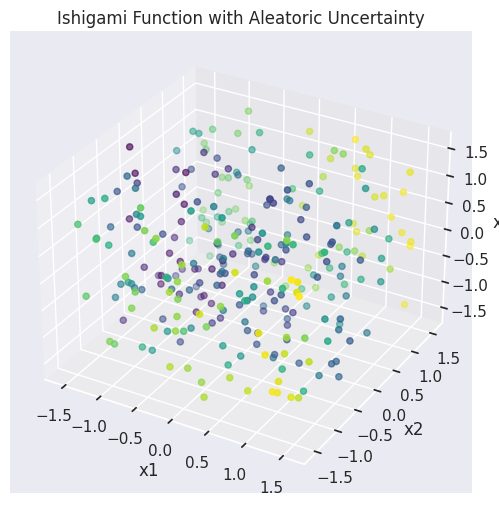

In [52]:
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x1, x2, x3, c=y, cmap='viridis')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('x3')
ax.set_title('Ishigami Function with Aleatoric Uncertainty')
plt.show()


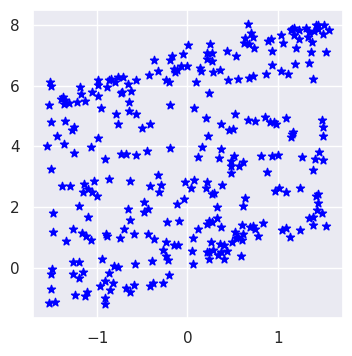

In [53]:

x1_train, y_train = x1,y
scatter(x1_train, y_train, c="blue", marker="*")


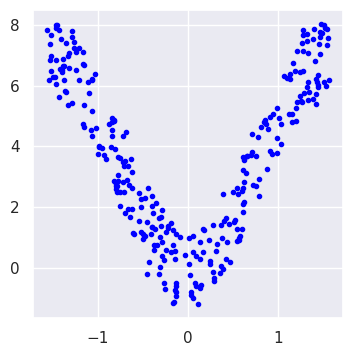

In [54]:
x2_train, y_train = x2,y
scatter(x2_train, y_train, c="blue", marker=".")

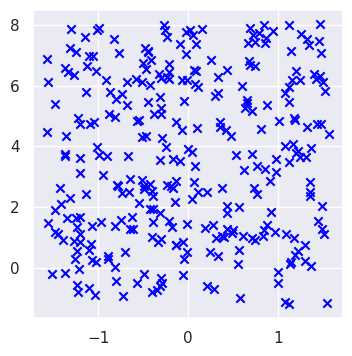

In [55]:
x3_train, y_train = x3,y
scatter(x3_train, y_train, c="blue", marker="x")

In [56]:
figure(figsize=(4, 4))
# Not exactely the same distribution, but works for now
x1_test, x2_test,x3_test, y_test = generate_ishigami_dataset(-np.pi, np.pi, 200)


<Figure size 400x400 with 0 Axes>

In [57]:
x1_test_tensor = torch.from_numpy(x1_test)
x2_test_tensor = torch.from_numpy(x2_test)
x3_test_tensor = torch.from_numpy(x3_test)

In [58]:
X_test=torch.stack((x1_test_tensor,x2_test_tensor,x3_test_tensor))
X_test=torch.transpose(X_test,0,1)

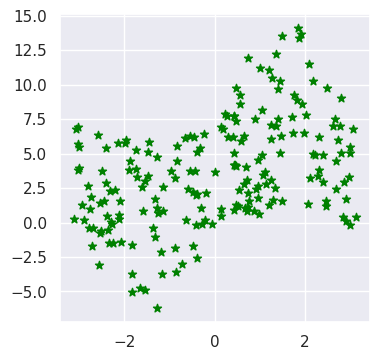

In [59]:
scatter(x1_test, y_test, c="green", marker="*")

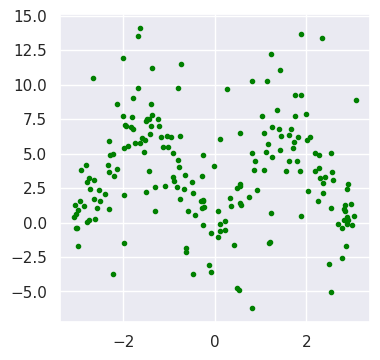

In [60]:
scatter(x2_test, y_test, c="green", marker=".")

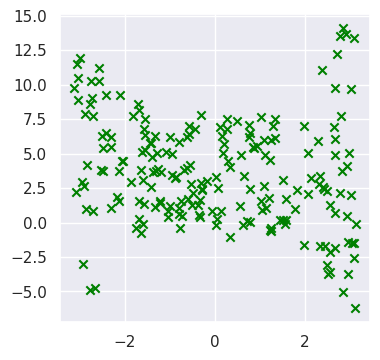

In [61]:
scatter(x3_test, y_test, c="green", marker="x")

In [62]:
def generate_ishigami_target_values(start, end, n_samples,x1,x2,x3):
    f_x = ishigami_function(x1, x2, x3)
    # Add variance to y
    y_var = 0.2
    y = np.random.normal(f_x, y_var,n_samples)
    return y

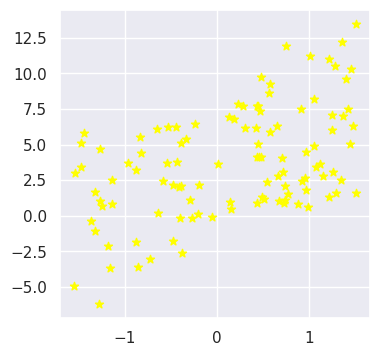

In [63]:
#Plotting In Training Distribution Data Points in the Test Set
# Filter the data to retain only the desired ranges
mask_x1_test_idd =  (x1_test >= start) &  (x1_test <= end) # Select the ranges -pi/2 to pi/2
x1_test_idd = x1_test[mask_x1_test_idd]
y1_test_idd = y_test[mask_x1_test_idd]

plt.figure(figsize=(4, 4))
plt.scatter(x1_test_idd, y1_test_idd, c="yellow", marker="*")

plt.show()


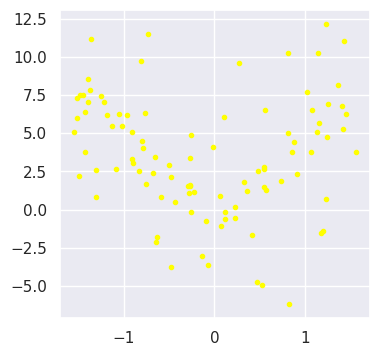

In [64]:
mask_x2_test_idd =  (x2_test >= start) &  (x2_test <= end) # Select the ranges -pi/2 to pi/2
x2_test_idd = x2_test[mask_x2_test_idd]
y2_test_idd = y_test[mask_x2_test_idd]

plt.figure(figsize=(4, 4))
plt.scatter(x2_test_idd, y2_test_idd, c="yellow", marker=".")

plt.show()

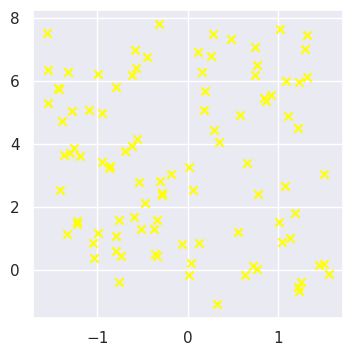

In [65]:
mask_x3_test_idd =  (x3_test >= start) &  (x3_test <= end) # Select the ranges -pi/2 to pi/2
x3_test_idd = x3_test[mask_x3_test_idd]
y3_test_idd = y_test[mask_x3_test_idd]

plt.figure(figsize=(4, 4))
plt.scatter(x3_test_idd, y3_test_idd, c="yellow", marker="x")

plt.show()

In [66]:


# Assuming x1_test_idd, x2_test_idd, and x3_test_idd are numpy arrays
x1_test_idd_tensor = torch.from_numpy(x1_test_idd)
x2_test_idd_tensor = torch.from_numpy(x2_test_idd)
x3_test_idd_tensor = torch.from_numpy(x3_test_idd)

# Find the tensor with the smallest length
min_length = min(x1_test_idd_tensor.shape[0], x2_test_idd_tensor.shape[0], x3_test_idd_tensor.shape[0])

# Slice the other tensors to match the length of the smallest tensor
tensor_x1_test_idd = x1_test_idd_tensor[:min_length]
tensor_x2_test_idd = x2_test_idd_tensor[:min_length]
tensor_x3_test_idd = x3_test_idd_tensor[:min_length]

# Print shapes of the tensors after slicing
print(tensor_x1_test_idd.shape)
print(tensor_x2_test_idd.shape)
print(tensor_x3_test_idd.shape)


torch.Size([97])
torch.Size([97])
torch.Size([97])


In [67]:
X_test_idd=torch.stack((tensor_x1_test_idd,tensor_x2_test_idd,tensor_x3_test_idd))
X_test_idd=torch.transpose(X_test_idd,0,1)

In [68]:
y_test_idd=generate_ishigami_target_values(start, end, X_test_idd.shape[0], tensor_x1_test_idd,tensor_x2_test_idd,tensor_x3_test_idd)

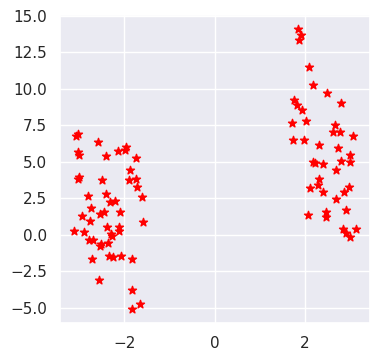

In [69]:
#Plotting Out of Training Distribution Data Points in the Test Set
# Filter the data to retain only the desired ranges
mask_x1_test_oodd = (x1_test >= -np.pi) & (x1_test < start) | (x1_test > end) & (x1_test <= np.pi) # Select the ranges -pi to -pi/2 and pi/2 to pi
x1_test_oodd = x1_test[mask_x1_test_oodd]
y1_test_oodd = y_test[mask_x1_test_oodd]

plt.figure(figsize=(4, 4))
plt.scatter(x1_test_oodd, y1_test_oodd, c="red", marker="*")

plt.show()


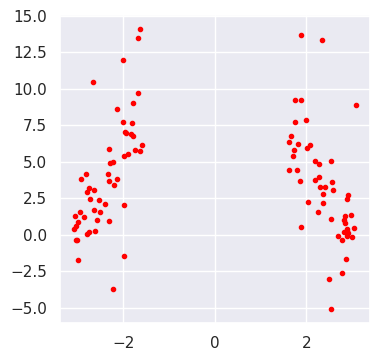

In [70]:
mask_x2_test_oodd = (x2_test >= -np.pi) & (x2_test < start) | (x2_test > end) & (x2_test <= np.pi) # Select the ranges -pi to -pi/2 and pi/2 to pi
x2_test_oodd = x2_test[mask_x2_test_oodd]
y2_test_oodd = y_test[mask_x2_test_oodd]

plt.figure(figsize=(4, 4))
plt.scatter(x2_test_oodd, y2_test_oodd, c="red", marker=".")

plt.show()

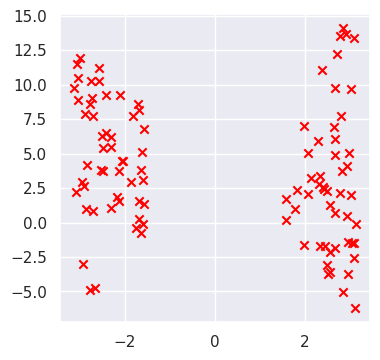

In [71]:
mask_x3_test_oodd = (x3_test >= -np.pi) & (x3_test < start) | (x3_test > end) & (x3_test <= np.pi) # Select the ranges -pi to -pi/2 and pi/2 to pi
x3_test_oodd = x3_test[mask_x3_test_oodd]
y3_test_oodd = y_test[mask_x3_test_oodd]

plt.figure(figsize=(4, 4))
plt.scatter(x3_test_oodd, y3_test_oodd, c="red", marker="x")

plt.show()

In [72]:
# Assuming x1_test_idd, x2_test_idd, and x3_test_idd are numpy arrays
x1_test_oodd_tensor = torch.from_numpy(x1_test_oodd)
x2_test_oodd_tensor = torch.from_numpy(x2_test_oodd)
x3_test_oodd_tensor = torch.from_numpy(x3_test_oodd)

# Find the tensor with the smallest length
min_length = min(x1_test_oodd_tensor.shape[0], x2_test_oodd_tensor.shape[0], x3_test_oodd_tensor.shape[0])

# Slice the other tensors to match the length of the smallest tensor
tensor_x1_test_oodd = x1_test_oodd_tensor[:min_length]
tensor_x2_test_oodd = x2_test_oodd_tensor[:min_length]
tensor_x3_test_oodd = x3_test_oodd_tensor[:min_length]

# Print shapes of the tensors after slicing
print(tensor_x1_test_oodd.shape)
print(tensor_x2_test_oodd.shape)
print(tensor_x3_test_oodd.shape)

torch.Size([92])
torch.Size([92])
torch.Size([92])


In [73]:
X_test_oodd=torch.stack((tensor_x1_test_oodd,tensor_x2_test_oodd,tensor_x3_test_oodd))
X_test_oodd=torch.transpose(X_test_oodd,0,1)

In [74]:
print(X_test_oodd.shape)

torch.Size([92, 3])


In [75]:
y_test_oodd=generate_ishigami_target_values(start, end, X_test_oodd.shape[0], tensor_x1_test_oodd,tensor_x2_test_oodd,tensor_x3_test_oodd)

In [76]:
X_train=X
# Train
tensor_x = torch.Tensor(X_train).unsqueeze(1)
tensor_y = torch.Tensor(y).unsqueeze(1)
train_dataset = TensorDataset(tensor_x, tensor_y)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

#Test for OODD (Out of Data Distribution)
tensor_x_test_oodd = torch.Tensor(X_test_oodd).unsqueeze(1)
tensor_y_test_oodd = torch.Tensor(y_test_oodd).unsqueeze(1)
test_dataset_oodd = TensorDataset(tensor_x_test_oodd, tensor_y_test_oodd)
test_loader_oodd = DataLoader(test_dataset_oodd, batch_size=batch_size, shuffle=True)

# #Test for IDD (In Data Distribution)
tensor_x_test_idd = torch.Tensor(X_test_idd).unsqueeze(1)
tensor_y_test_idd = torch.Tensor(y_test_idd).unsqueeze(1)
test_dataset_idd = TensorDataset(tensor_x_test_idd, tensor_y_test_idd)
test_loader_idd = DataLoader(test_dataset_idd, batch_size=batch_size, shuffle=True)

# Test
tensor_x_test = torch.Tensor(X_test).unsqueeze(1)
tensor_y_test = torch.Tensor(y_test).unsqueeze(1)
test_dataset = TensorDataset(tensor_x_test, tensor_y_test)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True)

In [77]:
tensor_x1_test=tensor_x_test[:200, 0, 0]
tensor_x2_test=tensor_x_test[:200, 0, 1]
tensor_x3_test=tensor_x_test[:200, 0, 2]
#Do we really need these?
X_test_x1 = X_test[:200, 0]
X_test_x2=X_test[:200,1]
X_test_x3=X_test[:200,2]

In [78]:
#Do we really need these?- yes
X_test_x1_oodd = X_test_oodd[:92, 0]
X_test_x2_oodd=X_test_oodd[:92,1]
X_test_x3_oodd=X_test_oodd[:92,2]

In [79]:
#Do we really need these?
X_test_x1_idd = X_test_idd[:97, 0]
X_test_x2_idd=X_test_idd[:97,1]
X_test_x3_idd=X_test_idd[:97,2]

In [80]:
class DeepONet(nn.Module):
    def __init__(self):
        super(DeepONet, self).__init__()
        self.hidden_size = 35

        # We have 3 input feature
        self.b1 = nn.Linear(3, self.hidden_size)
        self.b2 = nn.Linear(self.hidden_size, self.hidden_size)

        self.t1 = nn.Linear(self.hidden_size, self.hidden_size)
        self.t2 = nn.Linear(self.hidden_size, self.hidden_size)

        self.mu = nn.Linear(self.hidden_size, 1)
        self.var = nn.Linear(self.hidden_size, 1)

    def forward(self, x):
        x=x.type(torch.float32)
        h = torch.tanh(self.b1(x))
        h = torch.tanh(self.b2(h))

        input_noise = torch.normal(0, 1, size=(x.shape[0], self.hidden_size))

        t           = torch.tanh(self.t1(input_noise))
        t           = torch.tanh(self.t2(t))
        prod        = torch.multiply(t,h)

        mu = self.mu(prod)
        # Exponential activation to enforce positive var

        var = torch.exp(self.var(prod))
        return mu, var


In [81]:

def plot_with_confidence_interval_x2(model, tensor_xvar_test, tensor_y_test, xvar_test,y_test,color,start, end,tensor_x_test,X_test):
    # Get predictions
    mus = []
    vars = []

    for m in range(modelSamples):
        mu, var = model(tensor_x_test)

        mus.append(torch.mean(mu,axis=0))
        vars.append(torch.mean(var,axis=0))
    # For epistemic uncertainty we calculate the std on the mus!

    #means = torch.stack(mus).mean(axis=0).detach().numpy()

    # stds = torch.stack(vars).mean(axis=0).detach().numpy()**(1/2)
    # stds = torch.stack(mus).std(axis=0).detach().numpy()**(1/2) + \
    #             torch.stack(vars).mean(axis=0).detach().numpy()**(1/2)
    mus=torch.stack(mus)
    vars=torch.stack(vars)
    means=torch.mean(mus, axis=0).detach().numpy()

    stds=torch.std(mus,axis=0).detach().numpy()**(1/2) +torch.mean(vars,axis=0).detach().numpy()**(1/2)

    mu = means
    sigma = stds
    print("Shapes of tensor x test ", tensor_x_test.shape)
    print("Shapes of tensor y test ", tensor_y_test.shape)
    print("Shapes of x test ", X_test.shape)
    print("Shapes of y test ", y_test.shape)
    print("Shapes of mus ", means.shape)
    print("Shapes of sigma ", sigma.shape)
    # Calculate the 95% confidence interval
    #mu=torch.mean(mu, axis=0)
    lower_bound = mu - 2 * sigma
    upper_bound = mu + 2 * sigma
    print("Shapes of LB ", lower_bound.shape)
    # Count the data points within the confidence interval
    count_within_ci = np.sum((tensor_y_test.numpy() >= lower_bound) & (tensor_y_test.numpy() <= upper_bound))
    percentage_count_within_ci = (count_within_ci / tensor_y_test.shape[0]) * 100
    print(f'Number of data points within the 95% confidence interval: {count_within_ci}')
    print(f'Percentage of data points within the 95% confidence interval: {percentage_count_within_ci}')

    # ~ 95% conf. interval (see https://en.wikipedia.org/wiki/1.96)
    y_vals = [mu, mu + 2 * sigma, mu - 2 * sigma]
    dfs = []

    # Create DF from predictions
    for i in range(3):
        data = {
            "x": list(tensor_xvar_test.squeeze().numpy()),
            "y": list(y_vals[i].squeeze())
        }
        temp = pd.DataFrame.from_dict(data)
        dfs.append(temp)
    df = pd.concat(dfs).reset_index()

    # Plot predictions with confidence
    sns.set(rc={'figure.figsize': (4, 4)})
    sns_plot = sns.lineplot(data=df, x="x", y="y")

    # Highlight training range
    plt.axvline(x=start)
    plt.axvline(x=end)

    # Plot test data on top
    scatter(xvar_test, y_test, c=color, marker="*", alpha=0.5)
    plt.show()


    return percentage_count_within_ci


In [82]:


def train_and_evaluate_net_x2(net, train_loader, test_loader, tensor_xvar_test, tensor_y_test,  xvar_test,y_test,color, tensor_x_test, X_test, num_epochs=150, learning_rate=0.001):
    # Define loss and optimizer
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    criterion = torch.nn.GaussianNLLLoss(eps=1e-02)
    optimizer = optim.Adam(net.parameters(), lr=learning_rate)
    net.train()
    net.to(device)

    for epoch in range(num_epochs):
        # Train loop
        for batch in train_loader:
            x, y = batch[0].to(device), batch[1].to(device)
            optimizer.zero_grad()
            mu, var = net(x)
            loss = criterion(mu, y, var)
            loss.backward()
            optimizer.step()
            criterionmse_train = nn.MSELoss()
            mse_train = criterionmse_train(mu, y)
        if epoch % 10 == 0:
            all_test_losses = []
            all_mse_test = []
            # Test loop
            for batch in test_loader:
                x, y = batch[0].to(device), batch[1].to(device)
                mu, var = net(x)
                all_test_losses.append(criterion(mu, y, var).item())
                criterionmse_test = nn.MSELoss()
                all_mse_test.append(criterionmse_test(mu, y).item())
            test_loss = sum(all_test_losses) / len(all_test_losses)
            test_mse = sum(all_mse_test) / len(all_mse_test)
    percentage_count_within_ci=plot_with_confidence_interval_x2(net, tensor_xvar_test, tensor_y_test,xvar_test,y_test,color,start, end,tensor_x_test,X_test)
    return loss, test_loss, mse_train, test_mse,net,percentage_count_within_ci

def Neural_Network(net,train_loader,test_loader,tensor_xvar_test,tensor_y_test, xvar_test,y_test,color,tensor_x_test,X_test):
    loss, test_loss, mse_train, test_mse,net,percentage_count_within_ci = train_and_evaluate_net_x2(net, train_loader, test_loader,tensor_xvar_test,tensor_y_test, xvar_test,y_test,color,tensor_x_test,X_test)
    return loss, test_loss, mse_train, test_mse,net,percentage_count_within_ci



In [83]:

# Example JSON string
json_str = '''
{
  "test_loaders": ["test_loader", "test_loader_oodd", "test_loader_idd"],
  "test_tensors":["tensor_x_test","tensor_x_test_oodd","tensor_x_test_idd"],
  "test_tensors_x1":["tensor_x1_test","tensor_x1_test_oodd","tensor_x1_test_idd"],
  "test_tensors_x2":["tensor_x2_test","tensor_x2_test_oodd","tensor_x2_test_idd"],
  "test_tensors_x3":["tensor_x3_test","tensor_x3_test_oodd","tensor_x3_test_idd"],
  "test_tensors_y":["tensor_y_test","tensor_y_test_oodd","tensor_y_test_idd"],
  "color":["green","red","yellow"],
  "testset_x1":["X_test_x1","X_test_x1_oodd","X_test_x1_idd"],
  "testset_x2":["X_test_x2","X_test_x2_oodd","X_test_x2_idd"],
  "testset_x3":["X_test_x3","X_test_x3_oodd","X_test_x3_idd"],
  "testset_x":["X_test","X_test_oodd","X_test_idd"],
  "testset_y":["y_test","y_test_oodd","y_test_idd"],
  "output_dirs": ["pickled_models_", "pickled_models_oodd_", "pickled_models_idd_"],
  "error_metrics":["em","em_oodd","em_idd"]
}
'''

# Parse JSON
data = json.loads(json_str)

# Map string names to actual variables
test_loader_vars = {
    "test_loader": test_loader,
    "test_loader_oodd": test_loader_oodd,
    "test_loader_idd": test_loader_idd
}
tensor_x_mapping = {
    "tensor_x_test": tensor_x_test,
    "tensor_x_test_oodd": tensor_x_test_oodd,
    "tensor_x_test_idd": tensor_x_test_idd
}
tensor_x1_mapping = {
    "tensor_x1_test": tensor_x1_test,
    "tensor_x1_test_oodd": tensor_x1_test_oodd,
    "tensor_x1_test_idd": tensor_x1_test_idd
}
tensor_x2_mapping = {
    "tensor_x2_test": tensor_x2_test,
    "tensor_x2_test_oodd": tensor_x2_test_oodd,
    "tensor_x2_test_idd": tensor_x2_test_idd
}
tensor_x3_mapping = {
    "tensor_x3_test": tensor_x3_test,
    "tensor_x3_test_oodd": tensor_x3_test_oodd,
    "tensor_x3_test_idd": tensor_x3_test_idd
}

tensor_y_mapping = {
    "tensor_y_test": tensor_y_test,
    "tensor_y_test_oodd": tensor_y_test_oodd,
    "tensor_y_test_idd": tensor_y_test_idd
}
testset_x_mapping = {
    "X_test": X_test,
    "X_test_oodd": X_test_oodd,
    "X_test_idd": X_test_idd
}
testset_x1_mapping = {
    "X_test_x1": X_test_x1,
    "X_test_x1_oodd": X_test_x1_oodd,
    "X_test_x1_idd": X_test_x1_idd
}
testset_x2_mapping = {
    "X_test_x2": X_test_x2,
    "X_test_x2_oodd": X_test_x2_oodd,
    "X_test_x2_idd": X_test_x2_idd
}
testset_x3_mapping = {
    "X_test_x3": X_test_x3,
    "X_test_x3_oodd": X_test_x3_oodd,
    "X_test_x3_idd": X_test_x3_idd
}

# Mapping from string names to actual variables for testset_y
testset_y_mapping = {
    "y_test": y_test,
    "y_test_oodd": y_test_oodd,
    "y_test_idd": y_test_idd
}

# Access corresponding values using a loop
test_loaders = data["test_loaders"]
test_tensors=data["test_tensors"]
test_tensors_x1=data["test_tensors_x1"]
test_tensors_x2=data["test_tensors_x2"]
test_tensors_x3=data["test_tensors_x3"]
test_tensors_y=data["test_tensors_y"]
color=data["color"]
testset_x=data["testset_x"]
testset_x1=data["testset_x1"]
testset_x2=data["testset_x2"]
testset_x3=data["testset_x3"]
testset_y=data["testset_y"]
output_dirs = data["output_dirs"]
error_mets=data["error_metrics"]



Shapes of tensor x test  torch.Size([200, 1, 3])
Shapes of tensor y test  torch.Size([200, 1])
Shapes of x test  torch.Size([200, 3])
Shapes of y test  (200,)
Shapes of mus  (200, 1)
Shapes of sigma  (200, 1)
Shapes of LB  (200, 1)
Number of data points within the 95% confidence interval: 173
Percentage of data points within the 95% confidence interval: 86.5


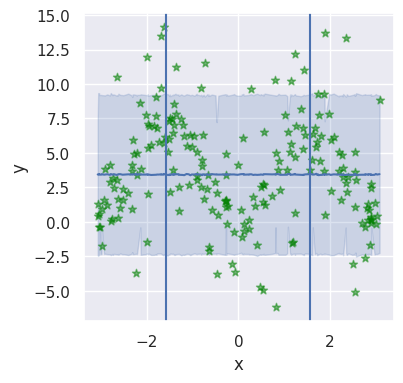

Shapes of tensor x test  torch.Size([200, 1, 3])
Shapes of tensor y test  torch.Size([200, 1])
Shapes of x test  torch.Size([200, 3])
Shapes of y test  (200,)
Shapes of mus  (200, 1)
Shapes of sigma  (200, 1)
Shapes of LB  (200, 1)
Number of data points within the 95% confidence interval: 175
Percentage of data points within the 95% confidence interval: 87.5


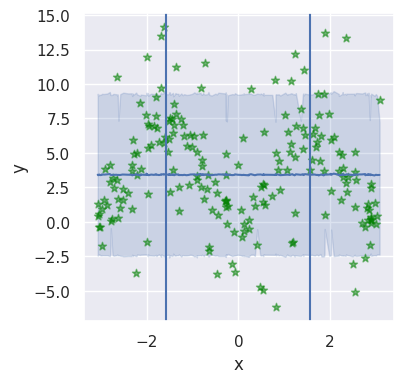

Shapes of tensor x test  torch.Size([200, 1, 3])
Shapes of tensor y test  torch.Size([200, 1])
Shapes of x test  torch.Size([200, 3])
Shapes of y test  (200,)
Shapes of mus  (200, 1)
Shapes of sigma  (200, 1)
Shapes of LB  (200, 1)
Number of data points within the 95% confidence interval: 173
Percentage of data points within the 95% confidence interval: 86.5


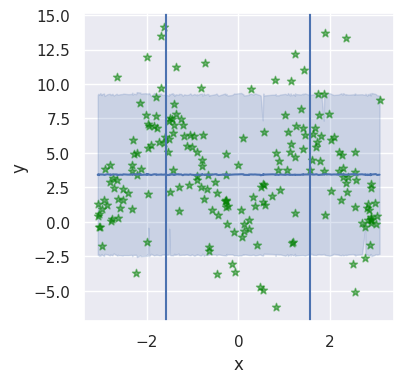

Shapes of tensor x test  torch.Size([200, 1, 3])
Shapes of tensor y test  torch.Size([200, 1])
Shapes of x test  torch.Size([200, 3])
Shapes of y test  (200,)
Shapes of mus  (200, 1)
Shapes of sigma  (200, 1)
Shapes of LB  (200, 1)
Number of data points within the 95% confidence interval: 174
Percentage of data points within the 95% confidence interval: 87.0


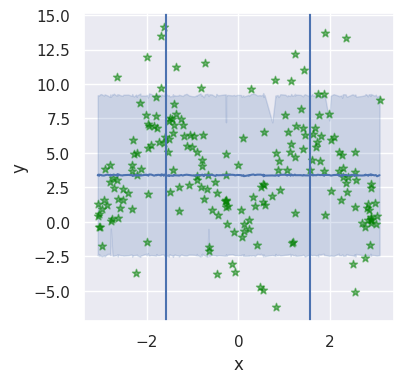

Shapes of tensor x test  torch.Size([200, 1, 3])
Shapes of tensor y test  torch.Size([200, 1])
Shapes of x test  torch.Size([200, 3])
Shapes of y test  (200,)
Shapes of mus  (200, 1)
Shapes of sigma  (200, 1)
Shapes of LB  (200, 1)
Number of data points within the 95% confidence interval: 173
Percentage of data points within the 95% confidence interval: 86.5


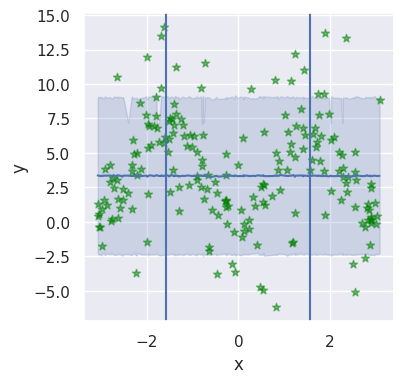

Shapes of tensor x test  torch.Size([200, 1, 3])
Shapes of tensor y test  torch.Size([200, 1])
Shapes of x test  torch.Size([200, 3])
Shapes of y test  (200,)
Shapes of mus  (200, 1)
Shapes of sigma  (200, 1)
Shapes of LB  (200, 1)
Number of data points within the 95% confidence interval: 175
Percentage of data points within the 95% confidence interval: 87.5


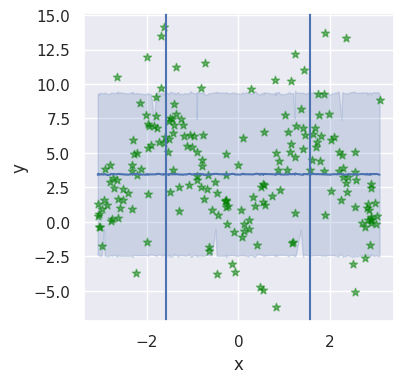

Shapes of tensor x test  torch.Size([200, 1, 3])
Shapes of tensor y test  torch.Size([200, 1])
Shapes of x test  torch.Size([200, 3])
Shapes of y test  (200,)
Shapes of mus  (200, 1)
Shapes of sigma  (200, 1)
Shapes of LB  (200, 1)
Number of data points within the 95% confidence interval: 173
Percentage of data points within the 95% confidence interval: 86.5


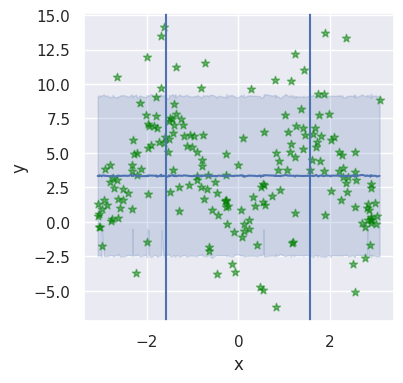

Shapes of tensor x test  torch.Size([200, 1, 3])
Shapes of tensor y test  torch.Size([200, 1])
Shapes of x test  torch.Size([200, 3])
Shapes of y test  (200,)
Shapes of mus  (200, 1)
Shapes of sigma  (200, 1)
Shapes of LB  (200, 1)
Number of data points within the 95% confidence interval: 173
Percentage of data points within the 95% confidence interval: 86.5


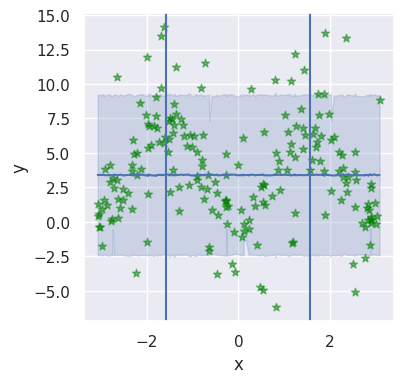

Shapes of tensor x test  torch.Size([200, 1, 3])
Shapes of tensor y test  torch.Size([200, 1])
Shapes of x test  torch.Size([200, 3])
Shapes of y test  (200,)
Shapes of mus  (200, 1)
Shapes of sigma  (200, 1)
Shapes of LB  (200, 1)
Number of data points within the 95% confidence interval: 174
Percentage of data points within the 95% confidence interval: 87.0


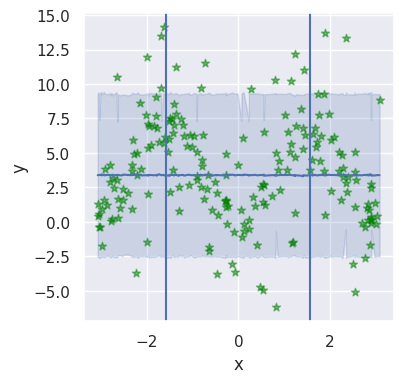

Shapes of tensor x test  torch.Size([200, 1, 3])
Shapes of tensor y test  torch.Size([200, 1])
Shapes of x test  torch.Size([200, 3])
Shapes of y test  (200,)
Shapes of mus  (200, 1)
Shapes of sigma  (200, 1)
Shapes of LB  (200, 1)
Number of data points within the 95% confidence interval: 174
Percentage of data points within the 95% confidence interval: 87.0


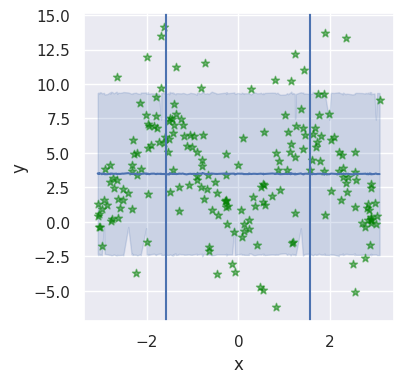

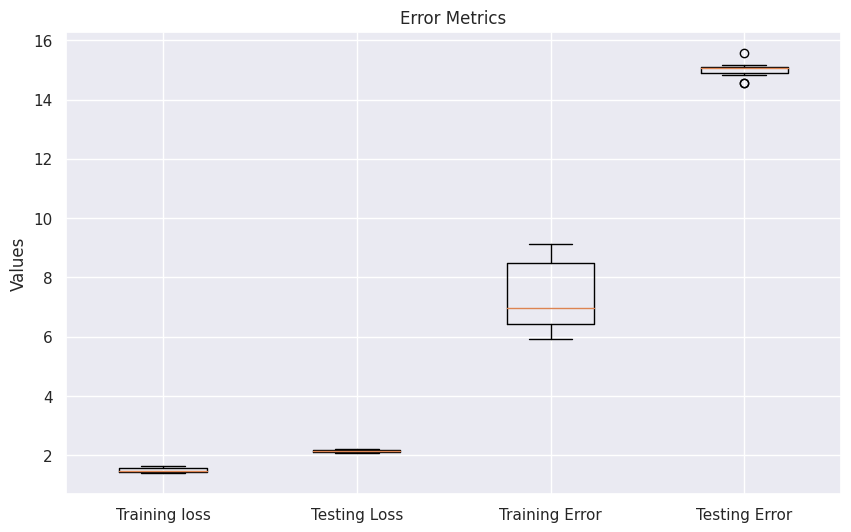

    Training Loss  Testing Loss  Mean Squared Training Error  \
1        1.482219      2.107045                     6.881116   
2        1.494099      2.156727                     7.170556   
3        1.583657      2.079276                     8.938297   
4        1.419319      2.199939                     6.223266   
5        1.635148      2.170891                     9.129829   
6        1.614598      2.133966                     9.038822   
7        1.438572      2.115003                     6.540868   
8        1.453730      2.185679                     6.411665   
9        1.412331      2.126848                     5.934445   
10       1.480068      2.180287                     7.085999   

    Mean Squared Testing Error  % of points in Confidence Interval  
1                    14.553715                                86.5  
2                    15.083176                                87.5  
3                    15.079795                                86.5  
4                  

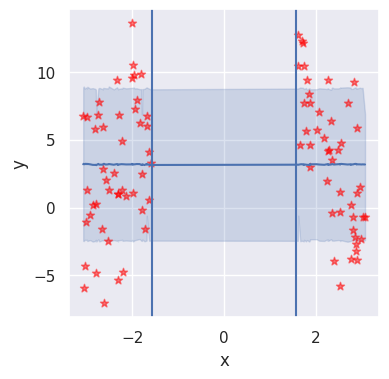

Shapes of tensor x test  torch.Size([92, 1, 3])
Shapes of tensor y test  torch.Size([92, 1])
Shapes of x test  torch.Size([92, 3])
Shapes of y test  (92,)
Shapes of mus  (92, 1)
Shapes of sigma  (92, 1)
Shapes of LB  (92, 1)
Number of data points within the 95% confidence interval: 64
Percentage of data points within the 95% confidence interval: 69.56521739130434


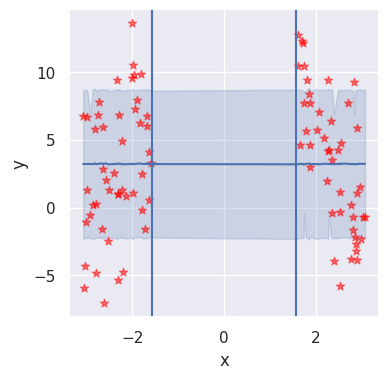

Shapes of tensor x test  torch.Size([92, 1, 3])
Shapes of tensor y test  torch.Size([92, 1])
Shapes of x test  torch.Size([92, 3])
Shapes of y test  (92,)
Shapes of mus  (92, 1)
Shapes of sigma  (92, 1)
Shapes of LB  (92, 1)
Number of data points within the 95% confidence interval: 64
Percentage of data points within the 95% confidence interval: 69.56521739130434


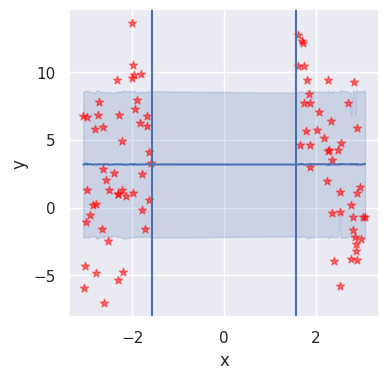

Shapes of tensor x test  torch.Size([92, 1, 3])
Shapes of tensor y test  torch.Size([92, 1])
Shapes of x test  torch.Size([92, 3])
Shapes of y test  (92,)
Shapes of mus  (92, 1)
Shapes of sigma  (92, 1)
Shapes of LB  (92, 1)
Number of data points within the 95% confidence interval: 65
Percentage of data points within the 95% confidence interval: 70.65217391304348


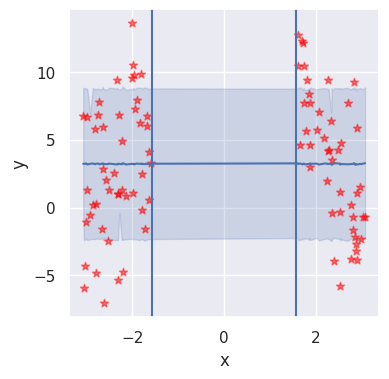

Shapes of tensor x test  torch.Size([92, 1, 3])
Shapes of tensor y test  torch.Size([92, 1])
Shapes of x test  torch.Size([92, 3])
Shapes of y test  (92,)
Shapes of mus  (92, 1)
Shapes of sigma  (92, 1)
Shapes of LB  (92, 1)
Number of data points within the 95% confidence interval: 64
Percentage of data points within the 95% confidence interval: 69.56521739130434


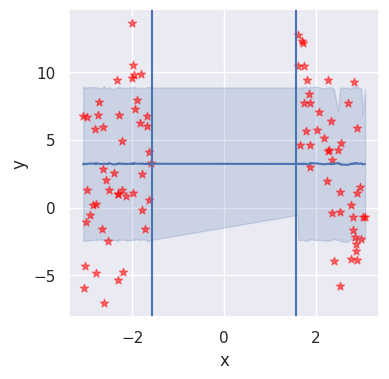

Shapes of tensor x test  torch.Size([92, 1, 3])
Shapes of tensor y test  torch.Size([92, 1])
Shapes of x test  torch.Size([92, 3])
Shapes of y test  (92,)
Shapes of mus  (92, 1)
Shapes of sigma  (92, 1)
Shapes of LB  (92, 1)
Number of data points within the 95% confidence interval: 63
Percentage of data points within the 95% confidence interval: 68.47826086956522


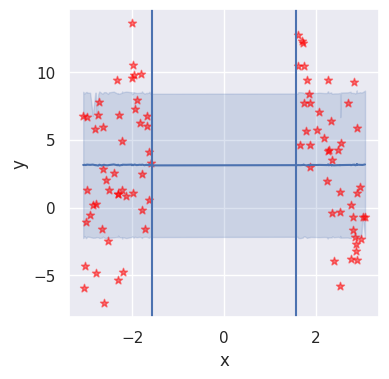

Shapes of tensor x test  torch.Size([92, 1, 3])
Shapes of tensor y test  torch.Size([92, 1])
Shapes of x test  torch.Size([92, 3])
Shapes of y test  (92,)
Shapes of mus  (92, 1)
Shapes of sigma  (92, 1)
Shapes of LB  (92, 1)
Number of data points within the 95% confidence interval: 66
Percentage of data points within the 95% confidence interval: 71.73913043478261


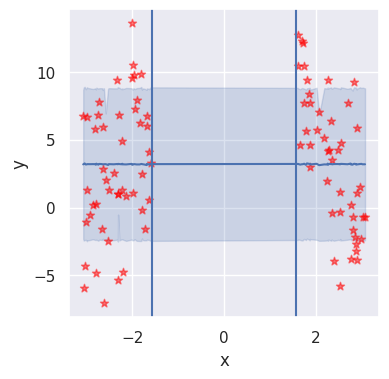

Shapes of tensor x test  torch.Size([92, 1, 3])
Shapes of tensor y test  torch.Size([92, 1])
Shapes of x test  torch.Size([92, 3])
Shapes of y test  (92,)
Shapes of mus  (92, 1)
Shapes of sigma  (92, 1)
Shapes of LB  (92, 1)
Number of data points within the 95% confidence interval: 63
Percentage of data points within the 95% confidence interval: 68.47826086956522


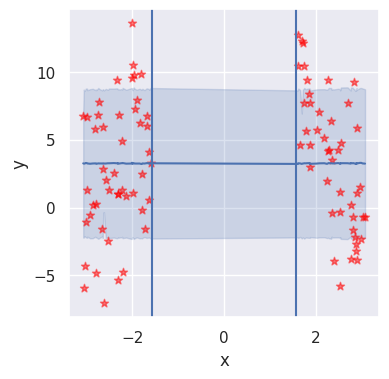

Shapes of tensor x test  torch.Size([92, 1, 3])
Shapes of tensor y test  torch.Size([92, 1])
Shapes of x test  torch.Size([92, 3])
Shapes of y test  (92,)
Shapes of mus  (92, 1)
Shapes of sigma  (92, 1)
Shapes of LB  (92, 1)
Number of data points within the 95% confidence interval: 65
Percentage of data points within the 95% confidence interval: 70.65217391304348


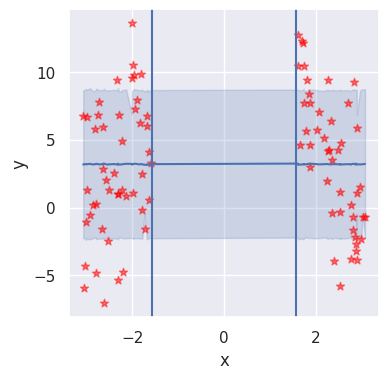

Shapes of tensor x test  torch.Size([92, 1, 3])
Shapes of tensor y test  torch.Size([92, 1])
Shapes of x test  torch.Size([92, 3])
Shapes of y test  (92,)
Shapes of mus  (92, 1)
Shapes of sigma  (92, 1)
Shapes of LB  (92, 1)
Number of data points within the 95% confidence interval: 65
Percentage of data points within the 95% confidence interval: 70.65217391304348


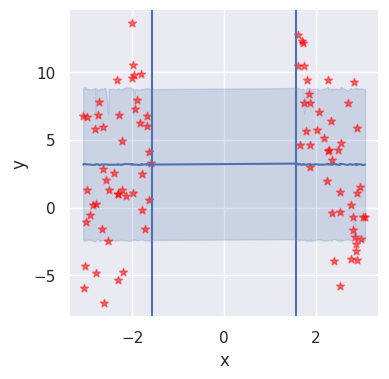

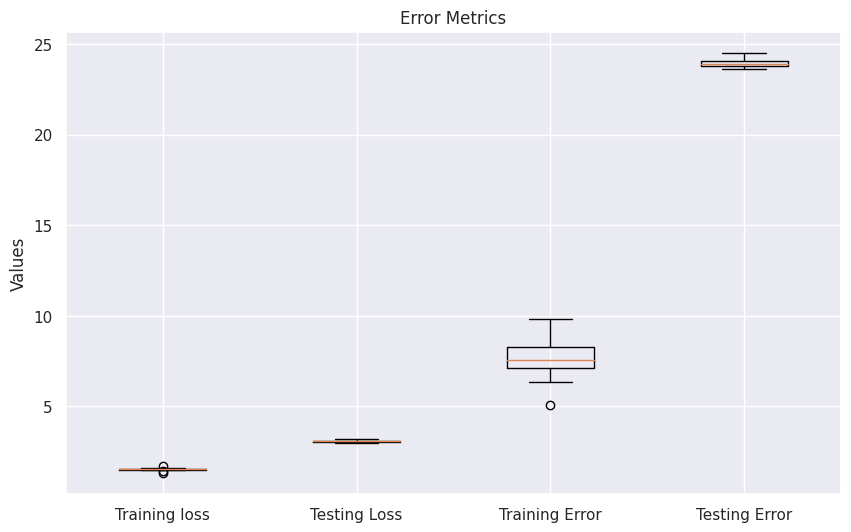

    Training Loss  Testing Loss  Mean Squared Training Error  \
1        1.546057      3.016539                     7.587522   
2        1.506565      3.058750                     7.074621   
3        1.336230      3.115849                     5.109518   
4        1.566426      3.006203                     8.444180   
5        1.513557      3.087258                     7.563845   
6        1.688873      3.176692                     9.821054   
7        1.503913      2.965391                     7.278087   
8        1.412619      3.075558                     6.335394   
9        1.597898      3.066371                     9.044093   
10       1.537083      3.134323                     7.864855   

    Mean Squared Testing Error  % of points in Confidence Interval  
1                    23.777818                           70.652174  
2                    23.961221                           69.565217  
3                    23.805257                           69.565217  
4                  

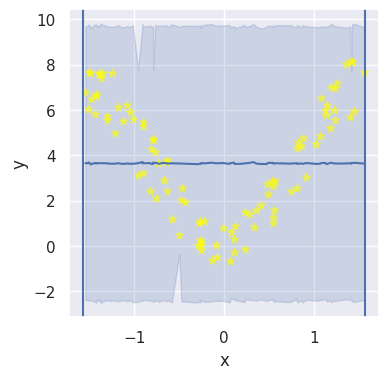

Shapes of tensor x test  torch.Size([97, 1, 3])
Shapes of tensor y test  torch.Size([97, 1])
Shapes of x test  torch.Size([97, 3])
Shapes of y test  (97,)
Shapes of mus  (97, 1)
Shapes of sigma  (97, 1)
Shapes of LB  (97, 1)
Number of data points within the 95% confidence interval: 97
Percentage of data points within the 95% confidence interval: 100.0


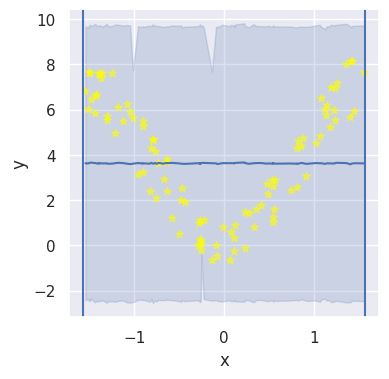

Shapes of tensor x test  torch.Size([97, 1, 3])
Shapes of tensor y test  torch.Size([97, 1])
Shapes of x test  torch.Size([97, 3])
Shapes of y test  (97,)
Shapes of mus  (97, 1)
Shapes of sigma  (97, 1)
Shapes of LB  (97, 1)
Number of data points within the 95% confidence interval: 97
Percentage of data points within the 95% confidence interval: 100.0


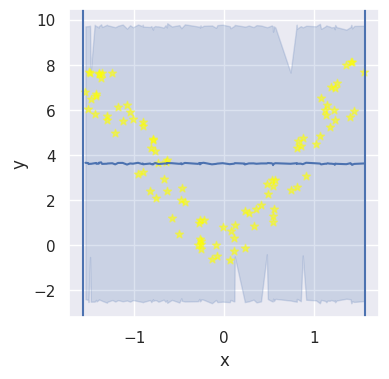

Shapes of tensor x test  torch.Size([97, 1, 3])
Shapes of tensor y test  torch.Size([97, 1])
Shapes of x test  torch.Size([97, 3])
Shapes of y test  (97,)
Shapes of mus  (97, 1)
Shapes of sigma  (97, 1)
Shapes of LB  (97, 1)
Number of data points within the 95% confidence interval: 97
Percentage of data points within the 95% confidence interval: 100.0


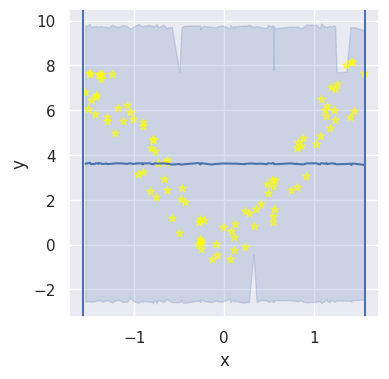

Shapes of tensor x test  torch.Size([97, 1, 3])
Shapes of tensor y test  torch.Size([97, 1])
Shapes of x test  torch.Size([97, 3])
Shapes of y test  (97,)
Shapes of mus  (97, 1)
Shapes of sigma  (97, 1)
Shapes of LB  (97, 1)
Number of data points within the 95% confidence interval: 97
Percentage of data points within the 95% confidence interval: 100.0


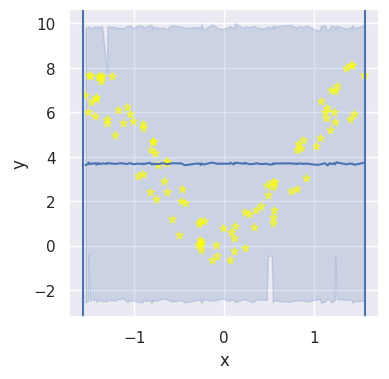

In [ ]:
for tst_loader,tnsor_xvar_test,tnsor_y_test, col, xvar_test,y_test,output_dir, error_metric, tnsor_x_test,x_test in zip(test_loaders,test_tensors_x2,test_tensors_y,color,testset_x2,testset_y,output_dirs,error_mets,test_tensors,testset_x):
  train_losses=[]
  test_losses=[]
  errors_train=[]
  errors_test=[]
  percentages_count_within_ci=[]
  for i in range(10):
    net=DeepONet()
    tr_loss,test_loss,mse_tr,mse_test,model,percentage_count_within_ci = Neural_Network(net,train_loader,test_loader_vars[tst_loader],tensor_x2_mapping[tnsor_xvar_test],tensor_y_mapping[tnsor_y_test],testset_x2_mapping[xvar_test],testset_y_mapping[y_test],col,tensor_x_mapping[tnsor_x_test],testset_x_mapping[x_test])
    error_metrics=tr_loss,test_loss,mse_tr,mse_test,model,percentage_count_within_ci
    model_filename = f"{output_dir}model_{i}.pkl"
    with open(model_filename, 'wb') as file:
      pickle.dump(error_metrics, file)
    train_losses.append(tr_loss)
    test_losses.append(test_loss)
    errors_train.append(mse_tr)
    errors_test.append(mse_test)
    percentages_count_within_ci.append(percentage_count_within_ci)
  # Extract numerical values from the tensors and remove grad_fn
  tr_loss_values= [tensor.item() for tensor in train_losses]
  test_loss_values=test_losses
  tr_errors_values= [tensor.item() for tensor in errors_train]
  test_errors_values= errors_test
  # Create a figure and axis
  fig, ax = plt.subplots(figsize=(10, 6))
  # Create box plots for each dataset
  box_plot_data = [tr_loss_values, test_loss_values, tr_errors_values, test_errors_values]
  box_labels = ['Training loss', 'Testing Loss', 'Training Error', 'Testing Error']
  ax.boxplot(box_plot_data, labels=box_labels)
  # Add labels and title
  ax.set_ylabel('Values')
  ax.set_title('Error Metrics')
  plt.savefig(f'donn_arch_{error_metric}.png', dpi=300)
  # Show the plot
  plt.show()

  mean_gaus_train_loss = np.mean(tr_loss_values)
  std_dev_gaus_train_loss = np.std(tr_loss_values)

  mean_gaus_test_loss = np.mean(test_loss_values)
  std_dev_gaus_test_loss = np.std(test_loss_values)

  mean_mse_train = np.mean(tr_errors_values)
  std_dev_mse_train = np.std(tr_errors_values)

  mean_mse_test = np.mean(test_errors_values)
  std_dev_mse_test = np.std(test_errors_values)

  mean_percentages_count_within_ci = np.mean(percentages_count_within_ci)
  std_dev_percentages_count_within_ci = np.std(percentages_count_within_ci)

  # Create a DataFrame from the lists
  data = {
    'Training Loss': tr_loss_values,
    'Testing Loss': test_loss_values,
    'Mean Squared Training Error': tr_errors_values,
    'Mean Squared Testing Error': test_errors_values,
    '% of points in Confidence Interval':percentages_count_within_ci,
  }



  num_columns = len(data)

  column_names = ['Training Loss','Testing Loss', 'Mean Squared Training Error','Mean Squared Testing Error','% of points in Confidence Interval']
  # Create a DataFrame with dynamic column names
  df = pd.DataFrame(data, columns=column_names)
  df.index += 1
  # Display the DataFrame as a table
  print(df)
  df.to_csv(f'donn_results_{error_metric}.txt', index=True)
  print('Mean of Gausiann Training Loss of 10 runs ', mean_gaus_train_loss)
  print('Standard Deviation of Gausiann Training Loss of 10 runs ' , std_dev_gaus_train_loss )

  print('Mean of Gausiann Testing Loss of 10 runs ',mean_gaus_test_loss )
  print('Standard Deviation of Gausiann Testing Loss of 10 runs ',std_dev_gaus_test_loss)

  print('Mean of MSE Training of 10 runs ',mean_mse_train)
  print('Standard Deviation of MSE Training of 10 runs ' , std_dev_mse_train)

  print('Mean of MSE Testing of 10 runs ',mean_mse_test )
  print('Standard Deviation of MSE Testing of 10 runs ', std_dev_mse_test)

  print('Mean of percentage of 95% conf interval for 10 runs in data',mean_percentages_count_within_ci)
  print('Standard Deviation of percentage of 95% conf interval for 10 runs in data ' , std_dev_percentages_count_within_ci)

  # File path
  file_path = f'donn_summary_{error_metric}.txt'

  # Open the file in write mode
  with open(file_path, 'w') as file:
    # Write the results to the file
    file.write('Mean of Gaussian Training Loss of 10 runs: {}\n'.format(mean_gaus_train_loss))
    file.write('Standard Deviation of Gaussian Training Loss of 10 runs: {}\n\n'.format(std_dev_gaus_train_loss))

    file.write('Mean of Gaussian Testing Loss of 10 runs: {}\n'.format(mean_gaus_test_loss))
    file.write('Standard Deviation of Gaussian Testing Loss of 10 runs: {}\n\n'.format(std_dev_gaus_test_loss))

    file.write('Mean of MSE Training of 10 runs: {}\n'.format(mean_mse_train))
    file.write('Standard Deviation of MSE Training of 10 runs: {}\n\n'.format(std_dev_mse_train))

    file.write('Mean of MSE Testing of 10 runs: {}\n'.format(mean_mse_test))
    file.write('Standard Deviation of MSE Testing of 10 runs: {}\n\n'.format(std_dev_mse_test))

    file.write('Mean of percentage of 95% conf interval for 10 runs in data {}\n'.format(mean_percentages_count_within_ci))
    file.write('Standard Deviation of percentage of 95% conf interval for 10 runs in data {}\n\n'.format(std_dev_percentages_count_within_ci))

  # Print a message indicating the file has been saved
  print(f'Results summary saved to {file_path}')
